# 00 · Exploring the data

What do prices, trading activity and liquidity look like across these stocks?

We start with Nhi Dinh’s volatility and liquidity exploration, then look at differences between stocks, the forecast targets and patterns that motivate our models.

The competition’s volatility target is used for background exploration only. The later price and spread forecasts use separate targets. Sections E1–E4 use development windows.

**Next:** [Forecasting and trading](01_forecasting_and_trading.ipynb). [All notebooks](RESEARCH_GUIDE.md).


## 0. Setup

Runs locally or in Colab. Data comes from the Kaggle competition
[`optiver-realized-volatility-prediction`](https://www.kaggle.com/competitions/optiver-realized-volatility-prediction/data)
(accept the competition rules on Kaggle first). Set `DATA_DIR` below, or the `OBF_DATA_DIR`
environment variable, to the extracted folder that contains `train.csv`, `book_train.parquet/` and
`trade_train.parquet/`. In Colab, the next cell clones the repository, installs the requirements and,
if `DATA_DIR` is empty, downloads the data with a `KAGGLE_API_TOKEN` stored in Colab Secrets.

In [ ]:
import os, sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/Erdos-Projects/fall-2026-short-horizon-forecasting"
DATA_DIR = os.environ.get("OBF_DATA_DIR", "")      # e.g. "/path/to/optiver-realized-volatility-prediction"
CONFIG = "configs/smoke.yaml"                       # "configs/default.yaml" for the full analysis

if IN_COLAB:
    if not Path("fall-2026-short-horizon-forecasting").exists():
        !git clone -q {REPO_URL}
    %cd fall-2026-short-horizon-forecasting
    %pip install -q -r requirements.txt
    %pip install -q -e .
    if not DATA_DIR:
        from google.colab import userdata
        import kagglehub
        os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")
        DATA_DIR = "/content/data/optiver-realized-volatility-prediction"
        kagglehub.competition_download("optiver-realized-volatility-prediction", output_dir=DATA_DIR)
else:
    root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
    os.chdir(root)
    sys.path.insert(0, str(root / "src"))

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from obforecast.config import Timing, load_config
from obforecast.data import ParquetSource, check_layout, resolve_data_dir, select_stocks
from obforecast.book import build_tables
from obforecast import pipeline

cfg = load_config(CONFIG)
timing = Timing.from_config(cfg)
data_dir = resolve_data_dir(DATA_DIR or None, cfg)
layout = check_layout(data_dir)
source = ParquetSource(data_dir)
stock_ids = select_stocks(layout["book_stocks"], cfg["run"]["stocks"])
print(f"run label: {cfg['run']['label']} | data: {data_dir} | stocks used: {len(stock_ids)} of {layout['train_stocks']}")
print({k: v for k, v in layout.items() if k not in ("book_stocks",)})

## Background · Realized volatility and liquidity

**Nhi Dinh.** The four panels examine the competition target, realized volatility against that target, WAP versus midpoint, and intrabucket spread/depth. This restores the original exploration; the final E1–E4 analysis below has a different, development-only scope.

This background cell describes the full source sample and is not used to select forecasting models. The original saved figure and summaries are retained below; execute with the data to regenerate them.

In [ ]:
train = pd.read_csv(data_dir / "train.csv")
STOCK_ID = int(stock_ids[0])
book = source.load("book", STOCK_ID).sort_values(["time_id", "seconds_in_bucket"])
trades = source.load("trade", STOCK_ID)


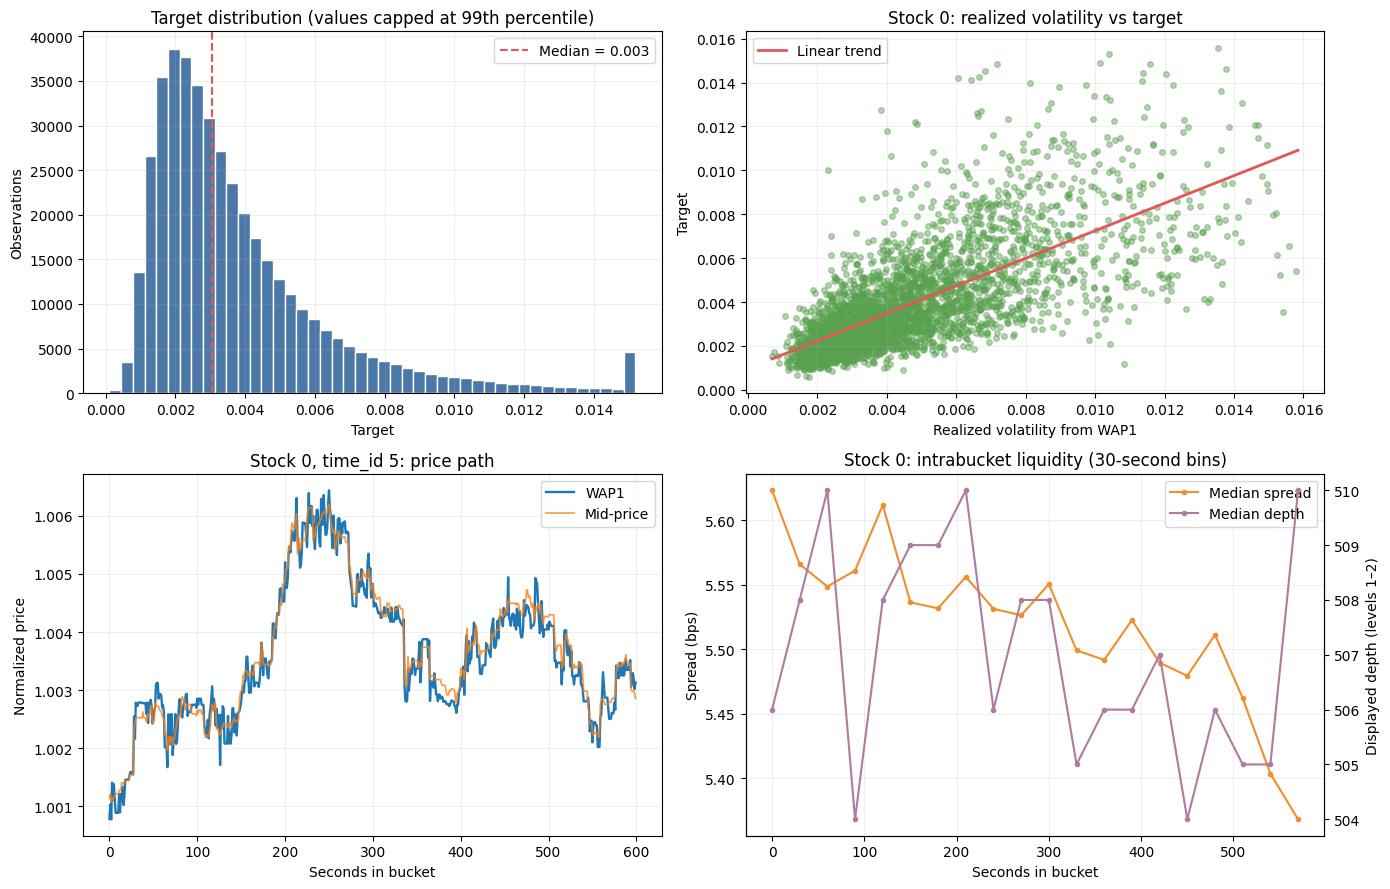

Eloise summary — stock 0
Target skewness (all stocks): 2.82
Correlation between book realized volatility and target: 0.718
Median spread: 5.52 bps
Median displayed depth: 507 shares


,target_summary
count,428932.000000
mean,0.003880
std,0.002936
min,0.000105
1%,0.000800
25%,0.002026
50%,0.003048
75%,0.004738
99%,0.015204
max,0.070321


In [ ]:
# Nhi Dinh — target, liquidity, and realized-volatility exploration
# This cell uses the train/book/trades objects created in the setup cells above.

book_eda = book.copy()
book_eda["mid_price"] = (book_eda["bid_price1"] + book_eda["ask_price1"]) / 2
book_eda["wap1"] = (
    book_eda["bid_price1"] * book_eda["ask_size1"]
    + book_eda["ask_price1"] * book_eda["bid_size1"]
) / (book_eda["bid_size1"] + book_eda["ask_size1"])
book_eda["spread_bps"] = (
    (book_eda["ask_price1"] - book_eda["bid_price1"])
    / book_eda["mid_price"] * 10_000
)
book_eda["total_depth"] = (
    book_eda[["bid_size1", "ask_size1", "bid_size2", "ask_size2"]].sum(axis=1)
)
book_eda["log_return"] = book_eda.groupby("time_id")["wap1"].transform(
    lambda s: np.log(s).diff()
)

rv = (book_eda.groupby("time_id")["log_return"]
      .apply(lambda s: np.sqrt(np.square(s.dropna()).sum()))
      .rename("realized_volatility")
      .reset_index())
rv_target = rv.merge(
    train.loc[train["stock_id"] == STOCK_ID, ["time_id", "target"]],
    on="time_id", how="inner"
)

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# 1) Target distribution across the full training set (trim only for display).
target_cap = train["target"].quantile(0.99)
axes[0, 0].hist(train["target"].clip(upper=target_cap), bins=45,
                color="#4C78A8", edgecolor="white")
axes[0, 0].axvline(train["target"].median(), color="#E45756", linestyle="--",
                   label=f'Median = {train["target"].median():.3f}')
axes[0, 0].set(title="Target distribution (values capped at 99th percentile)",
               xlabel="Target", ylabel="Observations")
axes[0, 0].legend()

# 2) Does realized volatility from the order book track the target?
x_cap = rv_target["realized_volatility"].quantile(0.99)
y_cap = rv_target["target"].quantile(0.99)
plot_points = rv_target[(rv_target["realized_volatility"] <= x_cap) &
                        (rv_target["target"] <= y_cap)]
axes[0, 1].scatter(plot_points["realized_volatility"], plot_points["target"],
                   s=16, alpha=0.45, color="#59A14F")
if len(plot_points) > 1 and plot_points["realized_volatility"].nunique() > 1:
    slope, intercept = np.polyfit(plot_points["realized_volatility"],
                                  plot_points["target"], 1)
    x_line = np.linspace(plot_points["realized_volatility"].min(), x_cap, 100)
    axes[0, 1].plot(x_line, slope * x_line + intercept, color="#E45756",
                    linewidth=2, label="Linear trend")
axes[0, 1].set(title=f"Stock {STOCK_ID}: realized volatility vs target",
               xlabel="Realized volatility from WAP1", ylabel="Target")
axes[0, 1].legend()

# 3) WAP and midpoint during a representative 10-minute bucket.
sample_time = int(book_eda["time_id"].drop_duplicates().iloc[0])
sample = book_eda[book_eda["time_id"] == sample_time]
axes[1, 0].plot(sample["seconds_in_bucket"], sample["wap1"],
                label="WAP1", linewidth=1.7)
axes[1, 0].plot(sample["seconds_in_bucket"], sample["mid_price"],
                label="Mid-price", linewidth=1.2, alpha=0.8)
axes[1, 0].set(title=f"Stock {STOCK_ID}, time_id {sample_time}: price path",
               xlabel="Seconds in bucket", ylabel="Normalized price")
axes[1, 0].legend()

# 4) Typical liquidity through the 10-minute bucket.
book_eda["second_bin"] = (book_eda["seconds_in_bucket"] // 30) * 30
liquidity_curve = book_eda.groupby("second_bin").agg(
    median_spread_bps=("spread_bps", "median"),
    median_depth=("total_depth", "median")
).reset_index()
ax_depth = axes[1, 1].twinx()
axes[1, 1].plot(liquidity_curve["second_bin"],
                liquidity_curve["median_spread_bps"], color="#F28E2B",
                marker="o", markersize=3, label="Median spread")
ax_depth.plot(liquidity_curve["second_bin"], liquidity_curve["median_depth"],
              color="#B07AA1", marker="o", markersize=3, label="Median depth")
axes[1, 1].set(title=f"Stock {STOCK_ID}: intrabucket liquidity (30-second bins)",
               xlabel="Seconds in bucket", ylabel="Spread (bps)")
ax_depth.set_ylabel("Displayed depth (levels 1–2)")
lines1, labels1 = axes[1, 1].get_legend_handles_labels()
lines2, labels2 = ax_depth.get_legend_handles_labels()
axes[1, 1].legend(lines1 + lines2, labels1 + labels2, loc="best")

for ax in axes.flat:
    ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

correlation = rv_target[["realized_volatility", "target"]].corr().iloc[0, 1]
print(f"Nhi Dinh summary — stock {STOCK_ID}")
print(f"Target skewness (all stocks): {train['target'].skew():.2f}")
print(f"Correlation between book realized volatility and target: {correlation:.3f}")
print(f"Median spread: {book_eda['spread_bps'].median():.2f} bps")
print(f"Median displayed depth: {book_eda['total_depth'].median():.0f} shares")
display(train["target"].describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99])
        .rename("target_summary").to_frame())

## 1. Coverage and one window

`check_layout` (above) confirms that every stock in `train.csv` has book and trade partitions.
`train.csv` holds the competition's volatility target, which this project does not use.
Below is one stock-window with the final timing marked.

In [ ]:
STOCK, WINDOW = stock_ids[0], None
book = source.load("book", STOCK)
trades = source.load("trade", STOCK)
WINDOW = WINDOW or int(book.time_id.iloc[0])
b, t = book[book.time_id == WINDOW], trades[trades.time_id == WINDOW]
mid = (b.bid_price1 + b.ask_price1) / 2

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True, gridspec_kw={"height_ratios": [2.2, 1]})
ax1.step(b.seconds_in_bucket, b.bid_price1, where="post", color="#2a78d6", lw=1.2, label="best bid (forward-filled)")
ax1.step(b.seconds_in_bucket, b.ask_price1, where="post", color="#eb6834", lw=1.2, label="best ask (forward-filled)")
ax1.step(b.seconds_in_bucket, mid, where="post", color="#0b0b0b", lw=1, label="mid")
ax1.scatter(t.seconds_in_bucket, t.price, s=10, color="#52514e", alpha=0.6, label="trade prints", zorder=3)
ax2.bar(t.seconds_in_bucket, t["size"], width=2, color="#52514e", label="trade size (shares)")
for ax in (ax1, ax2):
    ax.axvspan(0, timing.cut, color="#2a78d6", alpha=0.06)
    for x in (timing.cut - 1, timing.entry_second, timing.exit_second):
        ax.axvline(x, color="#52514e", ls=":", lw=1)
ax1.set(ylabel="normalised price", title=f"Stock {STOCK}, window {WINDOW}: inputs 0–{timing.cut - 1} (shaded), "
        f"buy at the ask at {timing.entry_second}, sell at the bid at {timing.exit_second}")
ax2.set(xlabel="second within the 10-minute window", ylabel="shares", xlim=(0, 600))
ax1.legend(loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False); ax2.legend(frameon=False)
plt.tight_layout(); plt.show()

## 2. Features, outcomes and data quality

The book is rebuilt on a one-second grid. Invalid level-1 snapshots (non-positive price or size,
crossed or locked quotes) are dropped; each second carries forward the latest valid quote **from the
same window only**; nothing is backfilled. The quote age separates stale-but-valid quotes from errors.

In [ ]:
# One pass over each stock's book: features (seconds 0..299), outcomes, data quality.
# Cached by obforecast.run under cache/ when you use the command line; here we build directly.
feats, outs, quality, invalid = build_tables(source, stock_ids, timing)
d = pipeline.prepare(feats, outs, cfg)   # legacy benchmark split + outer grouped folds
print(d.split_info)

In [ ]:
inv_cols = [c for c in invalid.columns if c != "stock_id"]
print("invalid level-1 snapshots dropped:", int(invalid[inv_cols].to_numpy().sum()) if inv_cols else 0)
print("windows excluded (no valid quote in seconds 0-299):", int(quality.no_initial_state.sum()), "of", len(quality))
kept = quality[~quality.no_initial_state]
display(kept[["age_last_feature", "age_entry", "age_exit"]].describe(percentiles=[0.5, 0.9, 0.99]).T
        .rename(index={"age_last_feature": "quote age at 299 (s)", "age_entry": "quote age at 300 (s)",
                       "age_exit": "quote age at 599 (s)"}).round(1))
print(f"entry ask older than {timing.stale_quote_seconds} s: {(kept.age_entry > timing.stale_quote_seconds).mean():.2%}")

## 3. How different are the stocks? (E1)

One typical value per stock (median over development windows) of the relative spread, displayed
level-1 depth and the number of seconds with a book update in 0–299. Large cross-stock differences
motivate stock-relative inputs (`*_vs_stock`, learned on training folds only) and a stock-mean baseline.

In [ ]:
dev_f, dev_o = d.dev_f, d.dev_o
e1 = dev_f.assign(spread_bps=np.exp(dev_f.log_S1) * 1e4, depth=np.exp(dev_f.log_depth1),
                  update_seconds=np.exp(dev_f.log_nupd))
stocks = e1.groupby("stock_id")[["spread_bps", "depth", "update_seconds"]].median()
display(stocks.quantile([0.1, 0.5, 0.9]).T.set_axis(["p10", "median", "p90"], axis=1).round(2))
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.hist(stocks.spread_bps, bins=20, color="#2a78d6", edgecolor="white")
ax.set(xlabel="typical relative spread (bps)", ylabel="number of stocks", title="E1. Typical spread by stock")
plt.tight_layout(); plt.show()

## 4. The two targets (E2)

* **Price:** `y_price = (m_599 / m_299 − 1) × 10⁴` (bps).
* **Spread:** `y_spread = log(S2/S1)`, with time-weighted mean relative spreads in 0–299 and 300–599.

The [spread-widening event classifier](04_spread_widening_events.ipynb) is a separate research branch: a second-half snapshot 90th percentile at least 1.5 times the first-half median. Both questions are retained.


In [ ]:
yp, ys = dev_o.y_price, dev_o.y_spread
display(pd.DataFrame({"price return (bps)": [yp.mean(), yp.std()], "log spread change": [ys.mean(), ys.std()]},
                     index=["mean", "SD"]).round(3))
print(f"spread widens in {(ys > 0).mean():.1%} of stock-windows; "
      f"Spearman(price, spread change) = {yp.corr(ys, method='spearman'):+.3f}")
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
for ax, y, label, color in [(axes[0], yp, "mid-price return 299→599 (bps)", "#eb6834"),
                            (axes[1], ys, "log(S2/S1)", "#2a78d6")]:
    lo, hi = y.quantile([0.005, 0.995])
    ax.hist(y[y.between(lo, hi)], bins=np.linspace(lo, hi, 41), histtype="step", lw=2, color=color)
    ax.set(xlabel=label, ylabel="stock-windows", title="central 99% of development observations")
plt.tight_layout(); plt.show()

## 5. First-half conditions vs future outcomes (E3)

Observations are ranked **within each stock** into quintiles of a first-half condition; each point
is the mean future outcome of the quintile. These are one-variable descriptive comparisons without
uncertainty intervals. The recent-spread condition and the spread target both use S1, so their
association alone does not show that a spread trend continues after second 299.

In [ ]:
d4 = dev_f.join(dev_o[["y_price", "y_spread"]])
def within_stock_quintile(col):
    return np.ceil(d4.groupby("stock_id")[col].rank(pct=True, method="first") * 5).clip(1, 5).astype(int)
conds = [("sp_last60", "y_spread", "recent spread vs first-half mean", "mean log spread change", "#2a78d6"),
         ("log_rv", "y_spread", "first-half volatility", "mean log spread change", "#2a78d6"),
         ("wap_tilt_now", "y_price", "order-book tilt at second 299", "mean price return (bps)", "#eb6834")]
curves = {}
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
for ax, (feat, target, title, ylabel, color) in zip(axes, conds):
    m = d4.groupby(within_stock_quintile(feat))[target].mean().reindex(range(1, 6))
    curves[feat] = m
    ax.plot(m.index, m.values, "o-", color=color, lw=2)
    ax.axhline(d4[target].mean(), color="#52514e", ls="--", lw=1)
    ax.set(title=title, xlabel="within-stock quintile (1 = lowest)", ylabel=ylabel, xticks=range(1, 6))
plt.tight_layout(); plt.show()
display(pd.DataFrame(curves).rename_axis("quintile").round(4))

## 6. Market context (E4)

Window averages across stocks describe the common move. Future window means are used here **only
for description**; model inputs use other stocks' first-half features (leave-one-out means), and
validation folds keep every stock of a window together.

In [ ]:
d5 = dev_f[["stock_id", "time_id", "ret_last60", "sp_last60"]].join(dev_o[["y_price", "y_spread"]])
w = d5.groupby("time_id")[["ret_last60", "sp_last60", "y_price", "y_spread"]].mean()
res = d5[["ret_last60", "y_price"]] - d5.groupby("time_id")[["ret_last60", "y_price"]].transform("mean")
corr = pd.Series({"market recent return vs market future return": w.ret_last60.corr(w.y_price),
                  "market recent spread vs market future spread change": w.sp_last60.corr(w.y_spread),
                  "own recent return vs own future return (window-demeaned)": res.ret_last60.corr(res.y_price)},
                 name="Pearson r")
display(corr.round(3).to_frame())
share = {t: 1 - ((d5[t] - d5.groupby("time_id")[t].transform("mean")) ** 2).mean() / d5[t].var()
         for t in ["y_price", "y_spread"]}
print("share of variance described by window means:", {k: f"{v:.1%}" for k, v in share.items()})

## 7. What the exploration motivates

| Evidence | Modelling choice evaluated in `01_forecasting_and_trading.ipynb` |
|---|---|
| Stocks differ in their normal spread, depth and activity | Stock-relative inputs (training-fold means) and a stock-mean baseline |
| Price and spread targets have different distributions and little rank association | Separate forecasts and separate model selection |
| Uneven, threshold-like spread responses; small directional price effects | Compare ridge regression and gradient boosting |
| Common movement across stocks within a window | Leave-one-out market inputs; validation grouped by window |